First 5 records:
   Study_Hours  Attendance_Percent  Previous_Marks  Sleep_Hours  \
0          3.6                  73              81          4.7   
1          7.7                  60              83          6.6   
2          6.1                  98              64          5.2   
3          5.2                  57              80          6.9   
4          2.1                  85              86          8.3   

   Assignment_Score  Final_Marks Performance  
0                94           92        High  
1                76          100        High  
2                67           98        High  
3                49           96        High  
4                78           86        High  

Training records: 160
Testing records: 40

First 10 actual categories:
['High', 'High', 'High', 'High', 'Medium', 'Medium', 'Medium', 'Medium', 'High', 'High']

First 10 predicted categories:
['Medium' 'High' 'High' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium'
 'High' 'High']

Random Forest Accur

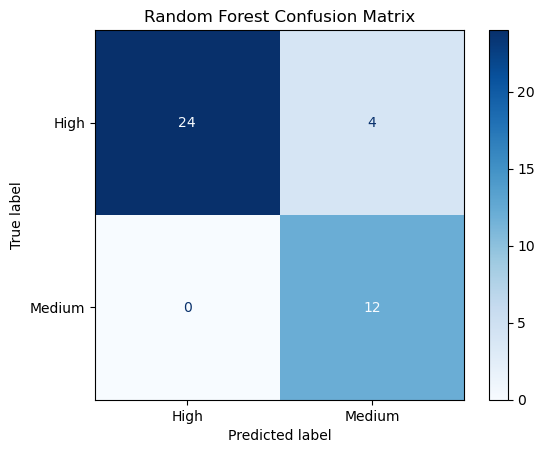


Feature Importance:
Study_Hours           0.531254
Attendance_Percent    0.178386
Previous_Marks        0.122315
Assignment_Score      0.103007
Sleep_Hours           0.065038
dtype: float64


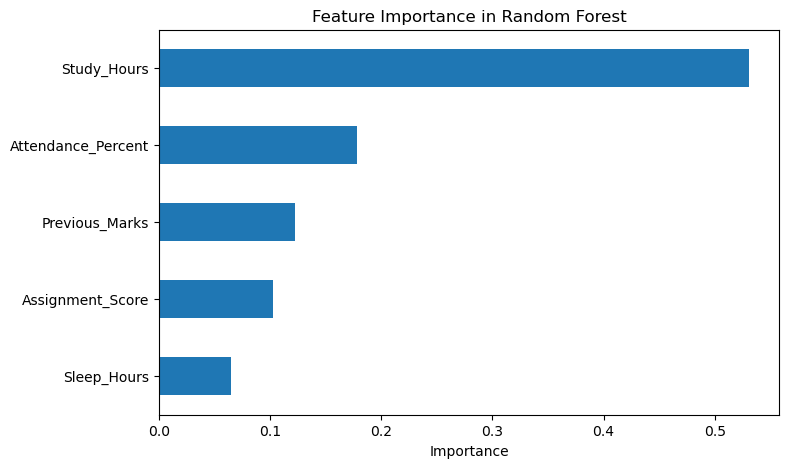

In [1]:

# Assignment 8: Random Forest Classification

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Step 2: Load dataset
df = pd.read_csv("Student_Performance_Dataset.csv")

print("First 5 records:")
print(df.head())

# Step 3: Select input features and target
features = [
    "Study_Hours",
    "Attendance_Percent",
    "Previous_Marks",
    "Sleep_Hours",
    "Assignment_Score"
]

X = df[features]
y = df["Performance"]

# Step 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# Step 5: Create and train Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Step 6: Make predictions
y_pred = model.predict(X_test)

print("\nFirst 10 actual categories:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted categories:")
print(y_pred[:10])

# Step 7: Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("\nRandom Forest Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(y.unique())
print("Class order:", labels)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=labels))

# Step 8: Display confusion matrix graph
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    display_labels=labels,
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

# Step 9: Display feature importance
importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

importance.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance in Random Forest")
plt.xlabel("Importance")
plt.show()


## Result
The Random Forest Classification algorithm was successfully implemented on the Student Performance Dataset. The model predicted student performance categories and was evaluated using accuracy, a classification report, and a confusion matrix.

## Conclusion
Random Forest combined predictions from multiple decision trees to classify student performance. Feature importance was also calculated to identify which input features contributed more to the model's predictions.